# Sydney Student Success & Employability Challenge (UTS MDSI, Kaggle 2026)
**Goal:** predict `successful_outcome` (1 = successful, 0 = not) for 5,000 students from 6 linked tables.
**Metric:** ROC-AUC (1.0 = perfect, 0.5 = guessing).

| Result | Score |
|---|---|
| 5-fold cross-validation (this notebook) | **0.978** |
| Kaggle public leaderboard (41% of test) | 0.98068 |
| Kaggle private leaderboard (final, 59% of test) | **0.98164** |

**Steps:** 1 Load - 2 Clean - 3 Summarise monthly data - 4 Join + new columns - 5 Model - 6 Check score - 7 Save submission

> **To run it:** download the data from the [competition page](https://www.kaggle.com/competitions/uts-mdsi-competition-2026/data), put the CSV files in a folder called `data/` next to this notebook, then run all cells. The data is not included in this repository.

## Step 1 - Load the data

In [1]:
import pandas as pd
import numpy as np
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold

FOLDER = "data/"      # put the competition CSV files in this folder

train    = pd.read_csv(FOLDER + "train.csv")                       # students + the answer
sample   = pd.read_csv(FOLDER + "sample_submission.csv")             # students we must predict
students = pd.read_csv(FOLDER + "students.csv")
profile  = pd.read_csv(FOLDER + "student_profile_metrics.csv")
monthly  = pd.read_csv(FOLDER + "student_monthly_activity.csv")      # many rows per student
suburbs  = pd.read_csv(FOLDER + "suburbs.csv")

print("Training students:", len(train), "| Students to predict:", len(sample))
train["successful_outcome"].value_counts()

Training students: 20000 | Students to predict: 5000


successful_outcome
1    14018
0     5982
Name: count, dtype: int64

## Step 2 - Clean the messy data
The data was made messy on purpose. The key lesson (and a mistake I made at first):
**not every extreme number is an error.** Some are just rare-but-real values (a student with 110% attendance score
is a natural tail, and it carries information). Only fix numbers that follow a *pattern of damage*.

In [ ]:
# Text: remove spaces + same capital letters  ("  iNdIa " -> "India")
students["country"]         = students["country"].str.strip().str.title()
students["degree_interest"] = students["degree_interest"].str.strip().str.title()
profile["transport_mode"]   = profile["transport_mode"].str.strip().str.title()

# Suburb 999 does not exist -> mark as missing
students.loc[~students["suburb_id"].isin(suburbs["suburb_id"]), "suburb_id"] = np.nan

In [1]:
# Commute: normal values are about 35 +/- 15 minutes. The huge ones (252, 484, 590...) are whole numbers
#     and are exactly 10x too big, so we divide by 10 and remember we did it with a flag column.
profile["commute_was_wrong"] = (profile["commute_time_minutes"] > 120).astype(int)
profile.loc[profile["commute_time_minutes"] > 120, "commute_time_minutes"] /= 10

# LinkedIn: real values are 20-1500. Bigger ones are all multiples of 20 (= real value x 20).
#     Those students almost always succeed (98.7%), so the FLAG itself is a strong clue. Keep both.
profile["linkedin_was_wrong"] = (profile["linkedin_connections"] > 1500).astype(int)
profile["linkedin_fixed"] = np.where(profile["linkedin_was_wrong"] == 1,
                                     profile["linkedin_connections"] / 20,
                                     profile["linkedin_connections"])

# Monthly table: remove repeated month rows, and impossible study hours (83-149 hours per week)
monthly = monthly.drop_duplicates(["student_id", "month_date"])
monthly.loc[monthly["study_hours"] > 80, "study_hours"] = np.nan

NameError: name 'profile' is not defined

## Step 3 - Summarise the monthly table
About 11 monthly rows per student -> we need ONE row per student. `groupby` + `agg` does that.

In [4]:
summary = monthly.groupby("student_id").agg(
    avg_study_hours        = ("study_hours", "mean"),
    total_networking       = ("networking_events", "sum"),
    avg_wellbeing          = ("wellbeing_score", "mean"),
    total_internship_hours = ("internship_hours", "sum"),
).reset_index()
summary.head()

,student_id,avg_study_hours,total_networking,avg_wellbeing,total_internship_hours
0,1,31.368145,17,76.230571,101
1,2,26.492140,17,65.631419,76
2,3,8.696965,24,67.285706,138
3,4,25.137810,20,77.035717,61
4,5,22.275601,21,57.885010,76


## Step 4 - Join everything + add 'warning sign' columns

In [5]:
data = (students
        .merge(profile, on="student_id")
        .merge(suburbs.drop(columns="suburb_name"), on="suburb_id", how="left")
        .merge(summary, on="student_id", how="left"))

# Looking at the data, success drops in clear STEPS (not smoothly):
#   part-time work: up to 15h = fine | 15-25h = lower | above 25h = collapses
#   commute:        up to 30 min = fine | 30-60 = lower | above 60 = collapses
data["work_level"]    = np.digitize(data["part_time_work_hours"], [15.01, 25.01])            # 0, 1 or 2
data["commute_level"] = np.digitize(data["commute_time_minutes"].fillna(35), [30, 60.0001])  # 0, 1 or 2
data["total_penalty"] = data["work_level"] + data["commute_level"]
data["works_too_much"] = (data["part_time_work_hours"] > 25).astype(int)
data["long_commute"]   = (data["commute_time_minutes"] > 60).astype(int)

word_columns = ["country", "gender", "degree_interest", "accommodation_type",
                "mobile_provider", "favourite_coffee", "transport_mode"]
for col in word_columns:
    data[col] = data[col].astype("category")

print("Table shape:", data.shape)

Table shape: (25000, 44)


## Step 5 - Train the model
Same model as before (HistGradientBoosting = many small decision trees, each fixing the last one's mistakes),
but with a **big discovery**: making each tree *smaller* (`max_leaf_nodes=3`) and using *more* trees made the score go UP.
Small trees can't memorise individual students, so they only learn real patterns.

In [6]:
train_data = train.merge(data, on="student_id")
X = train_data.drop(columns=["student_id", "successful_outcome"])   # clues
y = train_data["successful_outcome"]                                 # answer

model = HistGradientBoostingClassifier(
    learning_rate=0.05,
    max_iter=1000,           # 1000 tiny trees
    max_leaf_nodes=3,        # each tree is very small (only 2 questions deep)
    min_samples_leaf=40,
    l2_regularization=5,
    categorical_features="from_dtype",
    early_stopping=False,
    random_state=0,
)

## Step 6 - Check the score fairly (cross-validation)
Train on 4/5 of the students, test on the unseen 1/5, repeat 5 times.

In [7]:
folds  = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(model, X, y, cv=folds, scoring="roc_auc")

print("Score of each fold:", scores.round(4))
print("Average ROC-AUC   :", round(scores.mean(), 4))     # about 0.978

Score of each fold: [0.9769 0.9778 0.9795 0.9805 0.9755]
Average ROC-AUC   : 0.978


## Step 7 - Predict the test students and save

In [8]:
model.fit(X, y)

test_data = sample[["student_id"]].merge(data, on="student_id")
X_test    = test_data.drop(columns=["student_id"])

probabilities = model.predict_proba(X_test)[:, 1]      # chance of success (0 to 1)

submission = pd.DataFrame({"student_id": test_data["student_id"],
                           "successful_outcome": probabilities})
submission.to_csv("submission_final.csv", index=False)
submission.head()

,student_id,successful_outcome
0,18,0.999494
1,30,0.886035
2,31,0.999941
3,35,0.903718
4,36,0.138286


---
# Part 2 - Playground (experiment and watch the score)

In [9]:
def try_columns(columns):
    """Score a model that only sees these columns."""
    return round(cross_val_score(model, X[columns], y, cv=folds, scoring="roc_auc").mean(), 4)

print("All columns        :", try_columns(list(X.columns)))
print("Only internships   :", try_columns(["internships_completed"]))
print("Internships + work :", try_columns(["internships_completed", "part_time_work_hours"]))

All columns        : 0.978


Only internships   : 0.859


Internships + work : 0.9107


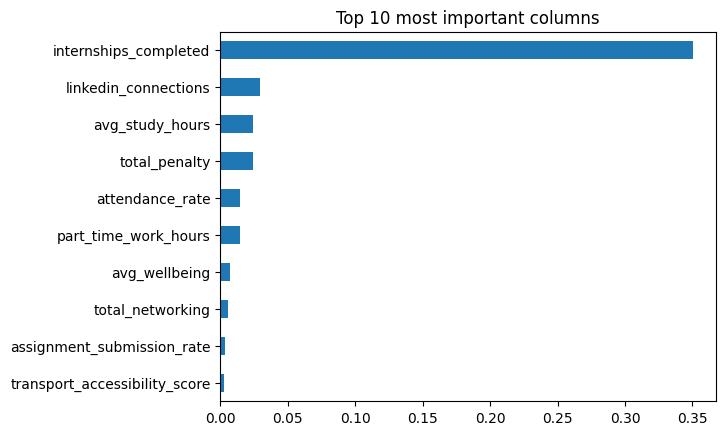

In [10]:
from sklearn.inspection import permutation_importance
rows = X.sample(4000, random_state=1)
r = permutation_importance(model, rows, y[rows.index], scoring="roc_auc", n_repeats=3, random_state=0)
pd.Series(r.importances_mean, index=X.columns).sort_values(ascending=False).head(10).plot(
    kind="barh", title="Top 10 most important columns").invert_yaxis()

In [11]:
# See the 'steps' yourself: success rate by work hours, split by internships
look = train_data.copy()
look["work_group"] = pd.cut(look["part_time_work_hours"], [-1, 15, 25, 30])
print(look.pivot_table(index="work_group", columns="internships_completed",
                       values="successful_outcome", aggfunc="mean").round(2))

internships_completed     0     1     2    3
work_group                                  
(-1, 15]               0.49  0.99  1.00  1.0
(15, 25]               0.31  0.97  1.00  1.0
(25, 30]               0.02  0.74  0.98  1.0



---
## Results and limits
- Cross-validation estimated **0.978**; the final private leaderboard score was **0.98164**, from one submission, so the model was not tuned to the public leaderboard.
- Biggest drivers: internships completed, then part-time work hours and commute time (success drops in steps above 25 h/week and 60 min), LinkedIn connections, attendance, study hours (best around 20 h/week) and wellbeing. Networking events and suburb matter for some groups.
- A mistake I fixed: my first cleaning capped high attendance and wellbeing values, but those were real values and carried signal.
- The top finishers scored about 0.003 higher on the private board. I tried other model types, blends and many extra features without closing that gap, so I don't know exactly what they did differently.